
<h2 style="text-align: center;">In the name of God </h2> 
<h1 style="text-align: center;">Signal and Systems </h1>
<h1 style="text-align: center;">Project Phase 2 </h1>
<h3 style="text-align: center;"> Mahyar Mohammad Alipoor<br><br> 402110684 </h3>

<br>


---

# Continuous Wavelet Transform (CWT)

The **Continuous Wavelet Transform (CWT)** is a time-frequency analysis tool that transforms a signal into a time-scale representation using a *wavelet* function. Unlike the Fourier Transform which uses sinusoids, CWT uses *wavelets* that are localized in both time and frequency.



Given a signal $ x(t) $, the Continuous Wavelet Transform is defined as:

$$
\mathcal{W}_x(a, b) = \frac{1}{\sqrt{|a|}} \int_{-\infty}^{\infty} x(t) \, \psi^*\left( \frac{t - b}{a} \right) dt
$$

Where $\psi(t)$ is the **Mother wavelet** defined as:

$$
\psi(t) = \pi^{-1/4} e^{i 2 \pi f_c t} e^{-t^2 / (2 \sigma^2)}
$$

* We can modify the central frequency $f_c$ and the number of cycles $n_{\text{cycles}} = f_c \cdot \sigma$ to our advanteges .
- $ \sigma $: Standard deviation (related to the width of the Gaussian envelope)

##  Why use CWT instead of Hilbert ?

While both CWT and the **Hilbert Transform** can extract phase and amplitude information from signals, CWT has several advantages:

###  CWT Advantages:
- **No need for filtering**: CWT directly analyzes all frequency components simultaneously. Hilbert requires preprocessing (e.g., bandpass filters) to isolate frequencies.
- **Time-localized phase and amplitude**: CWT gives phase and amplitude with better temporal resolution, especially in broadband or transient signals.
- **Robust to edge effects**: CWT handles signal boundaries better through wavelet padding, whereas Hilbert is sensitive to filter edge artifacts.

### ️ Hilbert Transform Limitations:
- Requires **narrowband filtering** before phase estimation.
- Sensitive to **filter design** and **band overlap**.



##  What can we change to get better results ?


#### Number of Cycles $ (n_{\text{cycles}}) $

- **Increasing `n_cycles` (i.e., increasing $ \sigma $)** : Better frequency resolution with narrower bandwidth in frequency domain and conversely Worse time resolution with wider in time domain .

- **Decreasing `n_cycles`** would yield results opposite to those of increasing `n_cycles`.

This trade-off arises from the **uncertainty principle**: we can't have arbitrarily high resolution in both time and frequency simultaneously.

#### Central Frequency $ (f_c) $

- **Increasing `f_c`**:
  - Shifts the wavelet to higher frequencies.
  For a fixed `n_cycles`, a higher $f_c $ implies **shorter wavelets** in time results in **better time resolution** at high frequencies.
  and Conversely, lower $f_c $ results in longer wavelets and with it **better frequency resolution** at low frequencies.

---

## Summary 

| Parameter | Increase Effect         | Decrease Effect              |
|--------|-------------------------|------------------------------|
| `n_cycles` | ↑ Frequency resolution<br>↓ Time resolution | ↓ Frequency resolution<br>↑ Time resolution |
| `f_c`  | Better time resolution  | Better frequency resolution  |

*Note :* we will use fewer cycles to capture transient events like sudden changes in the EEG signal .

---




# Computing MVL 





### **Step 1** : Extract epochs and loading data 
* we will extract the epochs and distinguish the data by their events using the following code :
```python
t_min , t_max = -2,5
raw = mne.io.read_raw_eeglab('Healthy.set', preload=True)
events, event_id = mne.events_from_annotations(raw)
epochs = mne.Epochs(raw, events, event_id=event_id,
                    tmin=t_min, tmax=t_max, baseline=None, preload=True)
epochs_A = epochs['5']
epochs_B = epochs['6']
data_A = epochs_A.get_data()  # shape: (nA, nCh, nT)
data_B = epochs_B.get_data()


sf = raw.info['sfreq']  # sampling rate
n_epochs, n_ch, n_t = data_A.shape

```


### **Step 2 :** Finding CWT
* Compute the CWT of the data using the following code (since we are using CWT , we don't need to be band filtering the data so we skip that part) 
* here we have used the function ```find_Mvl``` which would compute CWT for the set of frequencies given in ```freq1``` and ```freq2``` for the first and second channel passed onto it respectfully . 
```python
def find_Mvl(data, freq1 , freq2, ch1_idx, ch2_idx):
    
    sf = 250
    for i in range(len(freq1)):
        # Compute theta phase (low freq) and gamma amplitude (high freq)
        theta = tfr_array_morlet(data[:, [ch1_idx], :], sf, freqs=[freq1[i]], n_cycles=[3],
                                 use_fft=True, output='complex')[:, 0, 0, :]  
        gamma = tfr_array_morlet(data[:, [ch2_idx], :], sf, freqs=[freq2[i]], n_cycles=[3],
                                 use_fft=True, output='complex')[:, 0, 0, :]  

        phi = np.angle(theta) # shape (n_epochs, n_times)
        amp = np.abs(gamma) # shape (n_epochs, n_times)
```
* for the gamma band we have used central frequencies each $2.5$ Hz apart in the $[30,50]$ Hz interval .
* for the theta band we have used central frequencies each $0.5$ Hz apart in the $[4,8]$ Hz interval.

### **Step 3 :** Forming the complex vector and applying sliding window
* recall that the complex vector equation was 
$$
z(t) = A_\gamma(t) \cdot e^{j \phi_\theta(t)}
$$
so after creating this function using ```phi , amp ``` we then use the window width of $250$ samples (equivalent of a 1_second window) and a step width of $250 \times 0.05$ for creating the $95\%$ overlap window .
then we add the result to the dedicated trial-time array and return the result to be averaged across time and frequency 
* *these computation's were done under the given frequency at the for loop in *step_2** .
```python
mvl = np.zeros((n_epochs, n_steps))
step = int(0.05 * 250)
n_steps = (n_t - sf) // step + 1
sf=250
        
        
for e in range(n_epochs):
     for i in range(n_steps):
                start = i * step
                z = amp[e, start: start+sf] * np.exp(1j * phi[e, start:start + sf])
                mvl[e, i] = np.abs(np.mean(z))

mvl_freqs.append(mvl)  # shape per entry: (n_epochs, n_steps)
```


### **Step 4 :** taking the MVL mean across trial and frequency 
* Having found the **MVL** for a given central frequency in the shape of ```n_epoch , n_times``` we then average the result for the array of central frequencies and the number of trials to get the final result .
```python
mvl_freqs = find_Mvl(data, freq1 , freq2, channel_1, channel_2)
mvl_avg = mvl_freqs.mean(axis=0).mean(axis=0)  # mean over frequencies, then over trials
```


### **Step 5 :** Putting it all together
* we create a single function called ```Plot_Mvl(ch1 , ch2)``` which given two channels would plot the mvl for each subject and odor each stimulus.

In [26]:
import numpy as np
import matplotlib.pyplot as plt
import mne
from mne.time_frequency import tfr_array_morlet
import os
import warnings

warnings.filterwarnings(
    "ignore",
    message=".*Data file name in EEG\\.data.*",
    category=RuntimeWarning
)
mne.set_log_level('WARNING')


# ---------- SAVE FUNCTION ----------
def save_pac_data(base_path, state_name, subject_label, odor, ch_comb, pac_data):
    odor_name = f"Odor{odor}"
    output_folder = os.path.join(base_path, state_name, f"Subject_{subject_label}", odor_name, ch_comb)

    # Create the folder if it does not exist
    os.makedirs(output_folder, exist_ok=True)

    save_name = f"{state_name}_Subject_{subject_label}_{odor_name}_{ch_comb}.npz"
    save_path = os.path.join(output_folder, save_name)

    # Save using numpy compressed format
    np.savez(save_path, **pac_data)



# ---------- COMPUTE MVL ----------
def find_Mvl(data, freq1, freq2, ch1_idx, ch2_idx):
    sf = 250
    for i in range(len(freq1)):
        theta = tfr_array_morlet(data[:, [ch1_idx], :], sf, freqs=[freq1[i]], n_cycles=[10],
                                 use_fft=True, output='complex')[:, 0, 0, :]  # shape (n_epochs, n_times)
        gamma = tfr_array_morlet(data[:, [ch2_idx], :], sf, freqs=[freq2[i]], n_cycles=[10],
                                 use_fft=True, output='complex')[:, 0, 0, :]  # shape (n_epochs, n_times)

        phi = np.angle(theta)
        amp = np.abs(gamma)

        n_epochs, _, n_t = data.shape
        mvl_freqs = []
        step = int(0.05 * 250)
        n_steps = (n_t - sf) // step + 1
        mvl = np.zeros((n_epochs, n_steps))

        for e in range(n_epochs):
            for i in range(n_steps):
                start = i * step
                end = start + sf
                z = amp[e, start:end] * np.exp(1j * phi[e, start:end])
                mvl[e, i] = np.abs(np.mean(z))

        mvl_freqs.append(mvl)  # shape per entry: (n_epochs, n_steps)

    mvl_freqs = np.stack(mvl_freqs)  # shape: (n_freqs, n_epochs, n_steps)
    return mvl_freqs


# ---------- GET RESULT (NOW ALSO SAVES PAC DATA) ----------
def get_result(file_name, ch1, ch2, subject_label, base_save_path="PAC_Results"):
    t_min, t_max = -2, 5
    raw = mne.io.read_raw_eeglab(file_name, preload=True)
    events, event_id = mne.events_from_annotations(raw)

    # Extract epochs
    epochs = mne.Epochs(raw, events, event_id=event_id, tmin=t_min, tmax=t_max,
                        baseline=None, preload=True)
    epochs_5 = epochs['5']
    epochs_6 = epochs['6']
    data_5 = epochs_5.get_data()  # shape: (n_epochs, n_channels, n_times)
    data_6 = epochs_6.get_data()

    sf = raw.info['sfreq']
    _, _, n_t = data_5.shape
    picks1 = mne.pick_channels(raw.info['ch_names'], [ch1])[0]
    picks2 = mne.pick_channels(raw.info['ch_names'], [ch2])[0]

    freq1 = np.arange(4, 8, 0.5)  # theta: 4-8 Hz
    freq2 = np.arange(30, 50, 2.5)  # Gamma : 30-50 Hz

    win_n = 250
    step = int(0.05 * 250)
    n_steps = (n_t - win_n) // step + 1

    condition_data = {'5': data_5, '6': data_6}
    results = {}

    for cond, data in condition_data.items():
        mvl_freqs = find_Mvl(data, freq1, freq2, picks1, picks2)
        mvl_avg = mvl_freqs.mean(axis=0).mean(axis=0)  # mean over frequencies, then over trials
        results[cond] = mvl_avg

        # Prepare PAC data for saving
        pac_data = {
            'MVL_values': mvl_freqs,
            'MVL_mean': mvl_avg,
            'frequencies_theta': freq1,
            'frequencies_gamma': freq2,
            'time': np.arange(n_steps) * step / sf + t_min
        }

        # Save PAC data
        ch_comb = f"{ch1}_{ch2}"
        save_pac_data(
            base_path=base_save_path,
            state_name="MVL_Results",
            subject_label=subject_label,
            odor=cond,  # 5 or 6
            ch_comb=ch_comb,
            pac_data=pac_data
        )

    time = np.arange(n_steps) * step / sf + t_min
    return results['5'], results['6'], time


# ---------- PLOT FUNCTION ----------
def Plot_MVL(ch1, ch2):
    file_paths = {
        'Healthy': 'Healthy.set',
        'MCI': 'MCI.set',
        'AD': 'MAD.set'
    }

    results = np.empty((2, 3), dtype=object)
    for i, (subject_label, file_path) in enumerate(file_paths.items()):
        results[0][i], results[1][i], time = get_result(file_path, ch1, ch2, subject_label)

    fig, axs = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(f"MVL time series for channels {ch1} and {ch2}", fontsize=16)

    ax = axs[0]
    for i, subject_label in enumerate(file_paths.keys()):
        ax.plot(time, results[0][i], label=subject_label)
    ax.grid(True)
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('MVL')
    ax.set_title('Chocolate stimulus')
    ax.legend()

    ax = axs[1]
    for i, subject_label in enumerate(file_paths.keys()):
        ax.plot(time, results[1][i], label=subject_label)
    ax.grid(True)
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('MVL')
    ax.set_title('Rose stimulus')
    ax.legend()

    plt.tight_layout()
    plt.show()


*We will plot the results from parietal,frontal and rostro–caudal channel pairs*

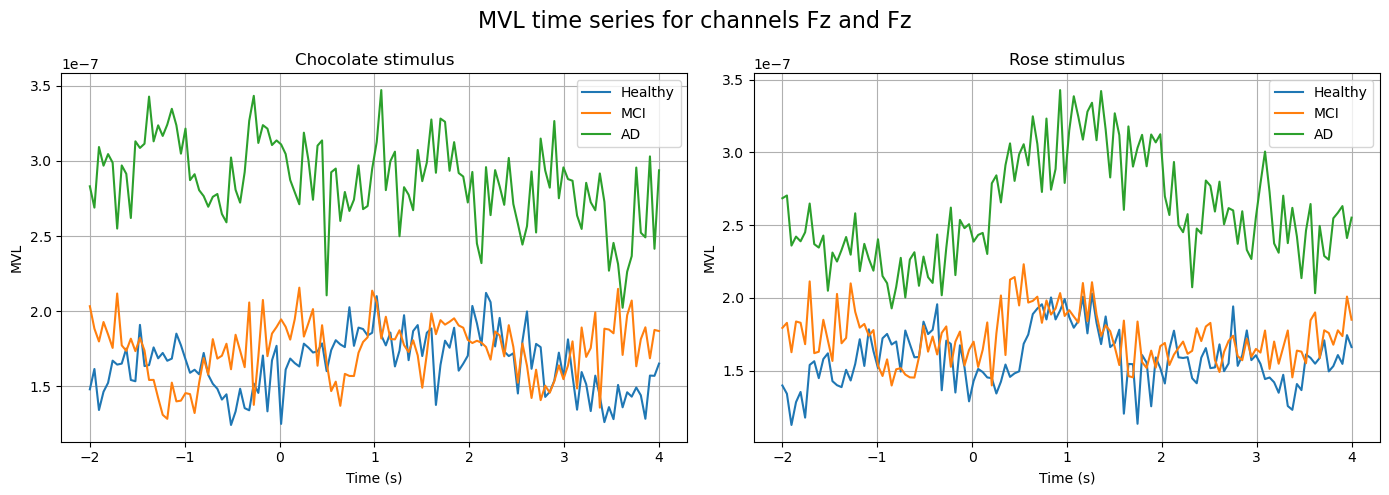

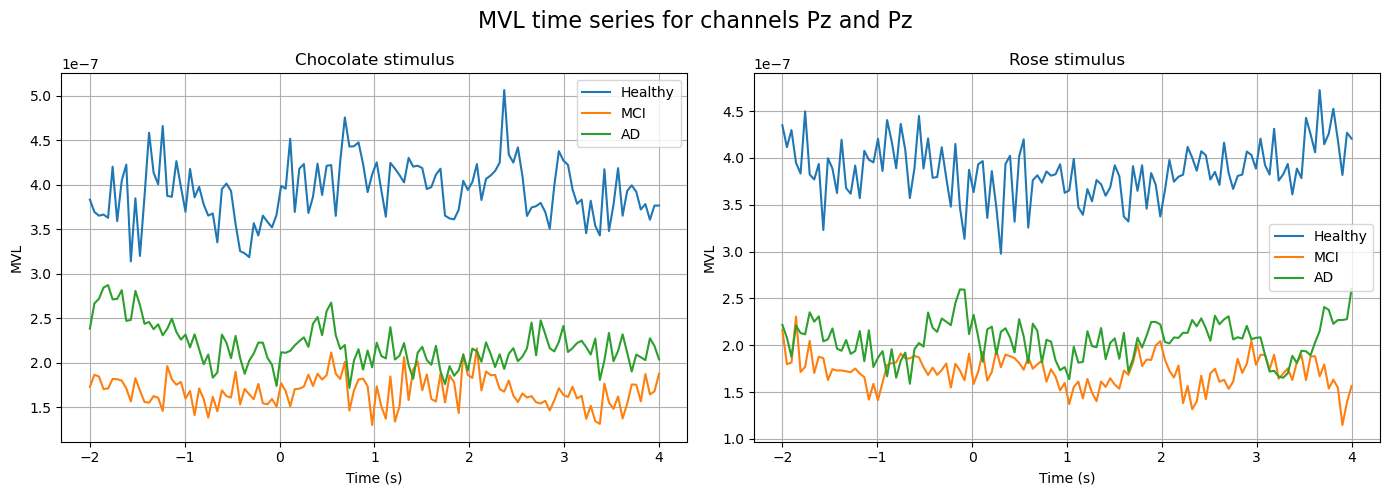

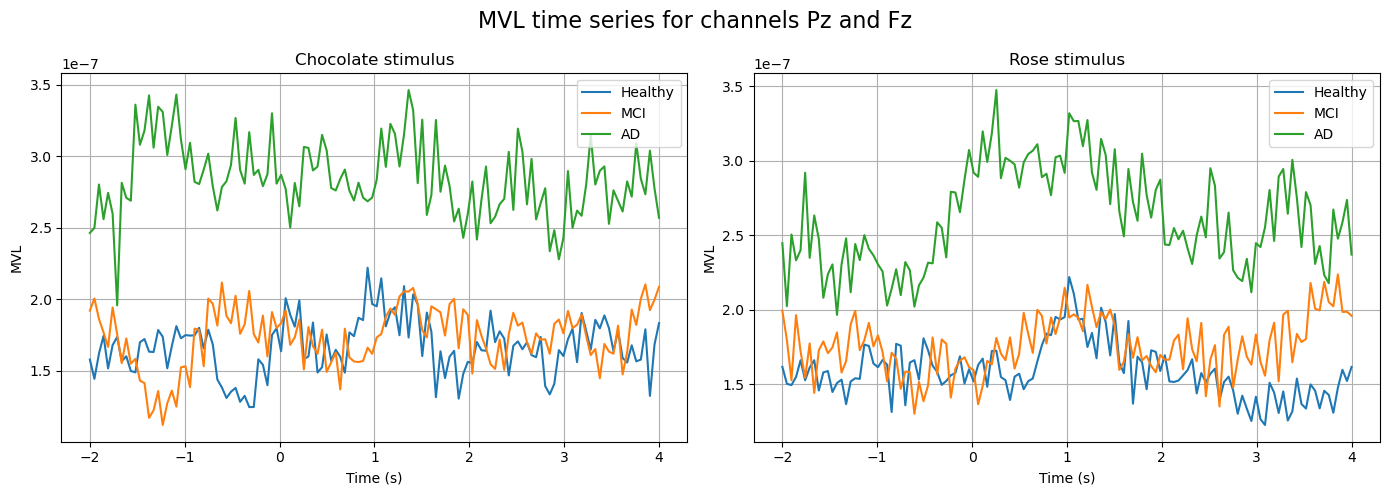

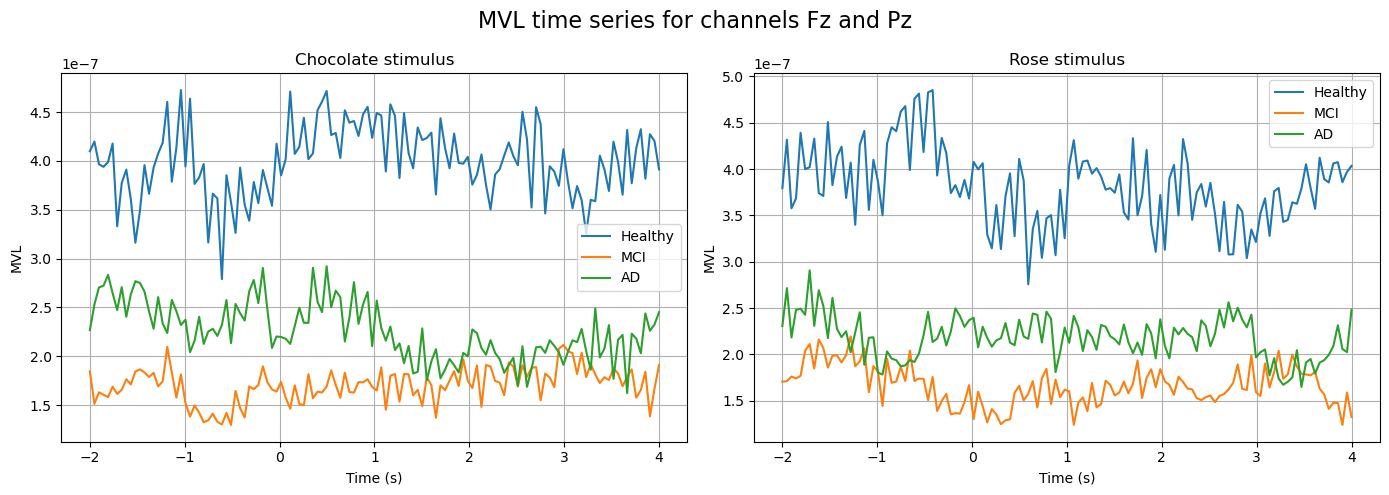

In [27]:
Plot_MVL('Fz','Fz')
Plot_MVL('Pz','Pz')
Plot_MVL('Pz' , 'Fz')
Plot_MVL('Fz' , 'Pz')

# Report: PAC (MVL) time-series across channels and subjects
Data shown: MVL time series of phase–amplitude coupling (PAC) for three subjects — Healthy, MCI, and AD — around stimulus onset at t = 0 s.  
Three channel pairs are plotted and repeated for two stimuli (Chocolate and Rose):

- Local frontal: Fz–Fz  
- Local parietal: Pz–Pz  
- Rostro–caudal (long-range): Fz–Pz  

MVL values are on the order of 10⁻⁷; the interpretation below focuses on relative differences (group/order, trends) rather than absolute magnitude.

---

## 1) Is there a clear increase in PAC during stimulus delivery?

Overall: Stimulus-locked increases are channel- and group-dependent, most evident in AD at frontal and long-range couplings, and in the Healthy subject at parietal sites for the Rose stimulus.

- Fz–Fz (frontal)
  - AD: Shows the *clearest* stimulus-locked rise: a pronounced bump peaking ~0.5–1 s after onset for both stimuli (higher and broader for Rose), followed by a gradual return. Typical range ≈ 2.7–3.3×10⁻⁷ post-stimulus, above its pre-stimulus level.
  - Healthy & MCI: Modest changes; brief upticks around 0.5–1 s may appear, but averages pre vs. post are similar (no robust step-like increase).

- Fz–Pz (rostro–caudal)
  - AD: Again shows a noticeable increase starting near 0 s (especially Rose), sustaining elevated MVL through ~2–3 s (≈ 2.6–3.2×10⁻⁷ post vs. ≈ 2.3–2.7×10⁻⁷ pre).
  - Healthy & MCI: Small, stimulus-time-locked modulations (Healthy: slight rise for Chocolate early; Rose is flat to slightly down). Changes are subtle compared with AD.

- Pz–Pz (parietal)
  - Healthy: For Rose, a gentle upward trend across the post-stimulus window (≈ 3.7→4.2×10⁻⁷); Chocolate is flatter with only transient wobbles.
  - MCI & AD: Mixed or small changes; AD increases slowly for Rose (≈ 2.1→2.6×10⁻⁷), but Chocolate shows little net gain.

Conclusion for Q1: There is a stimulus-related increase, but it is not global. It is most consistent and largest in AD at frontal and fronto–parietal couplings, and in Healthy at parietal sites for the Rose stimulus.

---

## 2) Are coupling dynamics consistent across trials and subjects?

Consistency across stimuli (Chocolate vs. Rose):  
The ordering of groups is strikingly stable across both stimuli (see Q3 for details). Temporal shapes also show repeatable motifs:

- AD: Reproducible early post-stimulus peaks (~0.5–1 s) in Fz–Fz and Fz–Pz for both stimuli; Rose produces a somewhat stronger/sustained elevation than Chocolate.
- Healthy: Pz–Pz stays high and relatively stable; Rose gently increases post-stimulus, Chocolate remains flat to mildly modulated.
- MCI: Low-amplitude, slow drifts with smaller stimulus-locked features across all channels.

Consistency across channels:
- Local vs. long-range:  
  - Frontal local (Fz–Fz): AD dominates; Healthy/MCI cluster lower.  
  - Parietal local (Pz–Pz): Healthy dominates; AD is intermediate; MCI is lowest.  
  - Cross (Fz–Pz): AD again leads; Healthy and MCI remain lower and close.

Conclusion for Q2: Yes — group ordering and temporal motifs are consistent across the two stimuli. Trial-to-trial micro-fluctuations exist, but the macro-pattern (who is high/low, where peaks occur) is stable.

---

## 3) Does the PAC pattern distinguish between cognitive states?

Yes — separation is robust and topography-dependent.

- Frontal (Fz–Fz):  
  AD » Healthy ≈ MCI. AD’s MVL (~2.8–3.2×10⁻⁷) sits clearly above the other two (~1.4–1.9×10⁻⁷), for both stimuli and across time. This yields strong discriminability of AD from non-AD.

---

---

# Comparison of PAC Measures: Modulation Index (MI) vs. MVL

###  Overview

Phase-amplitude coupling (PAC) quantifies how the phase of a low-frequency neural oscillation modulates the amplitude of a higher-frequency oscillation. Here, we compare two widely used metrics:

- **Modulation Index (MI)** – quantifies deviation from uniform phase distribution using Kullback–Leibler divergence  
- **Mean Vector Length (MVL)** – measures the average phasor length when high-frequency amplitude is mapped onto the low-frequency phase

---

## Behavior Under Different Conditions

| Feature | MVL | MI |
|---|---:|---:|
| Sensitivity to coupling | High | Lower |
| Robustness (noise / short recordings) | Low | High |
| Biphasic coupling | Misses it | Detects it |
| Recommended use | Long, clean, strong monophasic coupling | Noisy, short, or ambiguous data — general use |


##  Practical Implications in Our Analysis

- **Epoch Quality Affects Choice**  
  - *Healthy subjects* with cleaner EEG epochs are well-suited for MVL, maximizing sensitivity to nuanced coupling dynamics.  
  - *MCI or AD groups*, where signals may be noisier or shorter, benefit from MI’s robustness and greater tolerance to artifacts.

- **Interpretability by Condition**  
  - MVL excels in revealing subtle modulation strength differences in healthy or high‑SNR recordings.  
  - MI ensures detection reliability across challenging clinical populations—even if coupling patterns are complex (e.g., biphasic).

- **Complementary Reporting**  
  - When feasible, reporting both MI and MVL provides a more comprehensive view, balancing sensitivity and robustness :contentReference[oaicite:7]{index=7}.

---

##  Summary

- **MVL**: Excellent sensitivity for strong, clean, and long-duration coupling patterns.
- **MI**: More reliable under noisy conditions, adaptable to complex coupling forms.


## Implementing Modulation index

### **Step 1 :** band filtering and hilbert transform
* We begin by filtering our gamma and theta band data using the following code :
```python
def bandpass_filter(data, fs, band):
    nyq = fs / 2
    low, high = band[0] / nyq, band[1] / nyq
    b, a = butter(N=4, Wn=[low, high], btype='band')
    return filtfilt(b, a, data)
```
we then take the hilbert transform using :
```python
theta_filt = bandpass_filter(theta_data, fs, band_theta)
gamma_filt = bandpass_filter(gamma_data, fs, band_gamma)

# Extract phase and amplitude
theta_phase = np.angle(hilbert(theta_filt))
gamma_amp = np.abs(hilbert(gamma_filt))

```

### **Step 2 :** Calculating average amplitude per bin
* we divide the phase range into $18$ intervals and find the mean gamma amplitude that falls within that interval using :
```python
n_bins=18
bins = np.linspace(-np.pi, np.pi, n_bins + 1)
amp_binned = np.zeros(n_bins)

for i in range(n_bins):
        idx = (theta_phase >= bins[i]) & (theta_phase < bins[i + 1])
        amp_binned[i] = gamma_amp[idx].mean() if np.any(idx) else 0
``` 
* we then normalize the reuslting amplitude per bins to get a probability distribution :
```python
P = amp_binned / amp_binned.sum()
```

### **Step 3 :**  Kullback-Leibler divergence

#### What is Kullback–Leibler (KL) Divergence ?

The **KL divergence** measures how one probability distribution **P** is different from a second probability distribution **Q**. it tells us how much information is lost when we use **Q** to approximate **P**.

It is defined as:

$$
D_{KL}(P \parallel Q) = \sum_x P(x) \log \frac{P(x)}{Q(x)}
$$

- **P**: true distribution  
- **Q**: approximate or model distribution  
- **Dₖₗ ≥ 0** and is **0** only if $$P = Q $$
- It is **not symmetric**: $D_{KL}(P \parallel Q) \neq D_{KL}(Q \parallel P)$ 

* We implement this using the following code :
```python
uniform = np.ones(n_bins) / n_bins
kl_div = np.sum(P * np.log(P / uniform))

mi= kl_div / np.log(n_bins)

```



### **Step 4 :** Putting it all together 
* We define a function ```Plot_MI(channel_1 , channel_2)``` which would compute the MI index and plot the phase amplitude histograms.
##### **SideNote :** 
* I've also added a trial rejection function implementing `z_score` threshold and absolute amplitude value to get more valid trials.

In [16]:
import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, hilbert
import warnings
import os
warnings.filterwarnings(
    "ignore",
    message=".*Data file name in EEG\\.data.*",
    category=RuntimeWarning
)
mne.set_log_level('WARNING')
theta_band = (4, 8)
gamma_band = (30, 50)
fs = 250  # sampling rate
n_bins = 18

def bandpass_filter(data, fs, band):
    nyq = fs / 2
    low, high = band[0] / nyq, band[1] / nyq
    b, a = butter(N=4, Wn=[low, high], btype='band')
    return filtfilt(b, a, data)
def reject_noisy_trials(data_ch1, data_ch2, threshold_uv=30, z_thresh=4):
    clean_idx = []
    reject_count = 0
    
    for i in range(data_ch1.shape[0]):
        ch1 = data_ch1[i]
        ch2 = data_ch2[i]

        # Amplitude check
        amp_ok = (np.max(np.abs(ch1)) < threshold_uv and
                  np.max(np.abs(ch2)) < threshold_uv)
        # amp_ok=True
        # Z-score check
        z_ch1 = np.abs((ch1 - np.mean(ch1)) / np.std(ch1))
        z_ch2 = np.abs((ch2 - np.mean(ch2)) / np.std(ch2))
        z_ok = (np.max(z_ch1) < z_thresh and np.max(z_ch2) < z_thresh)
        
        if amp_ok and z_ok:
            clean_idx.append(i)
        else:
            reject_count += 1
    # print(f"Rejected trial {reject_count} passed trials : {len(clean_idx)}")
            

    return (data_ch1[clean_idx], data_ch2[clean_idx])

def compute_mi(theta_data, gamma_data, fs, band_theta, band_gamma, n_bins):
    # Filter signals
    theta_filt = bandpass_filter(theta_data, fs, band_theta)
    gamma_filt = bandpass_filter(gamma_data, fs, band_gamma)

    # Extract phase and amplitude...
    theta_phase = np.angle(hilbert(theta_filt))
    gamma_amp = np.abs(hilbert(gamma_filt))

    # Bin phase and average amplitude...
    bins = np.linspace(-np.pi, np.pi, n_bins + 1)
    bin_centers = (bins[:-1] + bins[1:]) / 2
    amp_binned = np.zeros(n_bins)

    for i in range(n_bins):
        idx = (theta_phase >= bins[i]) & (theta_phase < bins[i + 1])
        amp_binned[i] = gamma_amp[idx].mean() if np.any(idx) else 0

    # Normalize and compute MI...
    P = amp_binned / amp_binned.sum()
    uniform = np.ones(n_bins) / n_bins
    kl_div = np.sum(P * np.log(P / uniform))

    mi= kl_div / np.log(n_bins)

    return mi, bin_centers, P

def plot_pac(bin_centers, P, mi, title , ax , idx):
    P_norm = P*1/np.min(P)

    # Take log scale for plotting
    P_log = np.log(P_norm)

    color = {0: 'cyan', 1: 'red'}
    ax.set_title(f'{title}\n MI = {mi:.5f}', va='bottom')
    ax.bar(
        bin_centers,
        P_log,
        width=2 * np.pi / len(P),
        bottom=0.0,
        color=color[idx],
        alpha=0.7,
        edgecolor='black'
    )
    ax.set_yticklabels([])
def MI(path,channel_1 , channel_2,label):    
    t_min , t_max = -2,5
    raw = mne.io.read_raw_eeglab(path, preload=True,verbose=False)
    events, event_id = mne.events_from_annotations(raw)
    epochs = mne.Epochs(raw, events, event_id=event_id,
                        tmin=t_min, tmax=t_max, baseline=None, preload=True)
    epochs_5 = epochs['5']
    epochs_6 = epochs['6']
    epochs = {epochs_5 : 'Chocolate Stimuli', epochs_6 : 'Rose Stimuli'}
    
    
    fig, axs = plt.subplots(1, 2, subplot_kw={'projection':'polar'}, figsize=(11, 4))
    fig.suptitle(f"PAC for {label} \n Channels {channel_1} and {channel_2}", fontsize=13)
    
    # Extract and process each condition...
    for idx , epoch in enumerate(epochs.keys()):
        
        data = epoch.get_data()  # shape: (n_epochs, n_channels, n_times)
        data = data * 1e6  # convert to µV...
        
        # gather the data from the given channels ...
        picks_ch1 = mne.pick_channels(raw.info['ch_names'], [channel_1])
        picks_ch2 = mne.pick_channels(raw.info['ch_names'], [channel_2])
    
        data_ch1, data_ch2 = data[:, picks_ch1, :], data[:, picks_ch2, :]
         # Reject noisy epochs
        data_ch1, data_ch2 = reject_noisy_trials(data_ch1, data_ch2)
    
        
        # Arrays to hold results ...
        mi_values = []
        all_bin_centers = None
        all_P = []
        
        for trial in range(data_ch1.shape[0]):
            theta_trial = data_ch1[trial].ravel()
            gamma_trial = data_ch2[trial].ravel()
    
            mi, bin_centers, P = compute_mi(theta_trial, gamma_trial, fs,
                                            theta_band, gamma_band, n_bins)
            
            mi_values.append(mi)
            all_P.append(P)

            if all_bin_centers is None:
                all_bin_centers = bin_centers  # store bin centers once

        mean_mi = np.mean(mi_values)
        mean_P = np.mean(np.vstack(all_P), axis=0)
        plot_pac(all_bin_centers, mean_P, mean_mi , title=f"{epochs[epoch]}" , ax=axs[idx] , idx=idx)

        pac_data = {
    'MI_values': mi_values,
    'mean_MI': mean_mi,
    'bin_centers': all_bin_centers,
    'mean_P': mean_P
}

# Save (Example path and parameters)
        save_pac_data(
    base_path='PAC_Results',
    state_name='PAC_final',
    subject_number=label.replace(' subject', ''),  # e.g., 'Healthy'
    odor=idx+5,  # odor 5 or 6 based on condition
    ch_comb=f"{channel_1}_{channel_2}",
    pac_data=pac_data
)

    # Plot
        
def save_pac_data(base_path, state_name, subject_number, odor, ch_comb, pac_data):
    odor_name = f"Odor{odor}"
    output_folder = os.path.join(base_path, state_name, f"Subject{subject_number}", odor_name, ch_comb)

    # Create the folder if it does not exist
    os.makedirs(output_folder, exist_ok=True)

    save_name = f"{state_name}_Subject{subject_number}_{odor_name}_{ch_comb}.npz"
    save_path = os.path.join(output_folder, save_name)

    # Save using numpy compressed format
    np.savez(save_path, **pac_data)

    # print(f"PAC data saved at: {save_path}")

def Plot_MI(channel_1 , channel_2) :
    file_paths = {
        'Healthy subject':'Healthy.set',
        'MCI subject' : 'MCI.set',
        'AD subject' : 'MAD.set'
    }
    for (label , path) in file_paths.items():
        MI(path,channel_1,channel_2,label)     


---

## Electrode Selection and Anatomical Considerations

* We now answer the question of *What electrode pairs should we use ?*

### Recommended EEG Channel Pairs for PAC

Based on recent EEG studies in cognitive impairment and Alzheimer’s:

- **Parietal within-channel PAC:**  
  Use `P3–P3` and `P4–P4` (theta→gamma). These sites often show **decreasing PAC** from Healthy → MCI → AD. ([PMC article](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC9396580/?utm_source=chatgpt.com))

- **Temporal-parietal cross-channel PAC:**  
  Compute PAC from `T3 (phase) → P3 (amplitude)` and `T4 → P4`. Reflects network-level declines in MCI/AD.

- **Midline task-evoked PAC (odor/cognition):**  
  Evaluate `Fz`, `Pz` individually. These channels have shown significant PAC differences across groups in olfactory tasks ([ResearchGate figure](https://www.researchgate.net/figure/Theta-Gamma-Phase-Amplitude-Coupling-PAC-for-healthy-controls-and-aMCI-and-AD-patients_fig3_362873871)).
  
- **Frontal polar channels:**

  Evaluate `Fp1` → `Fz`, and `Fp1` → `Fz` pairs , these are Frontal-polar sites that capture odor-related brain dynamics (e.g., prefrontal responses to fragrance)



### Summary

- **Use P3/P4 within-channel** first — simplest and most reliable.
- **Add T3→P3 / T4→P4** to assess regional coupling loss.
- **Include Fz, Cz, Pz** for MVL time-series in stimulus-driven paradigms.



#### We start the interpretation by choosing channels `Pz` and `Fz` :

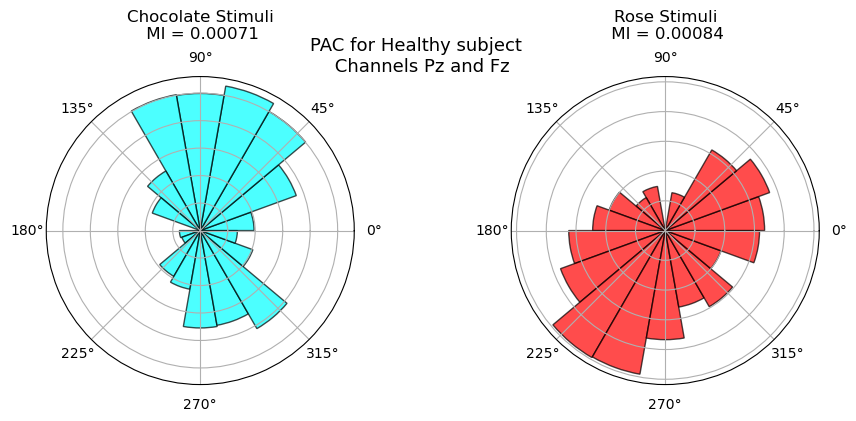

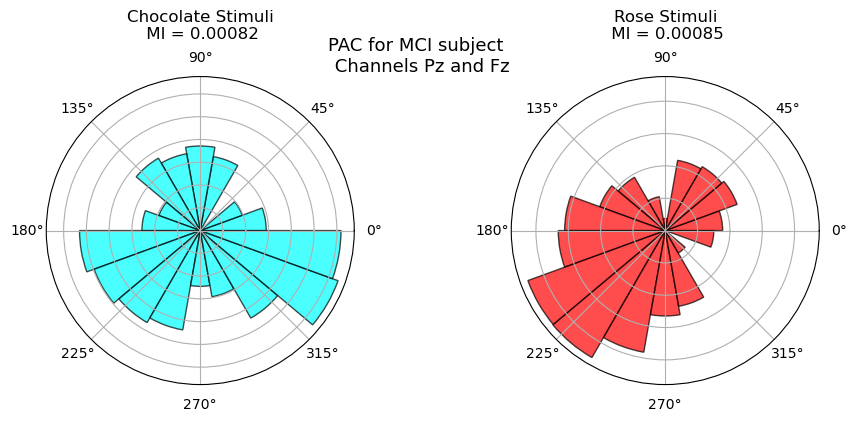

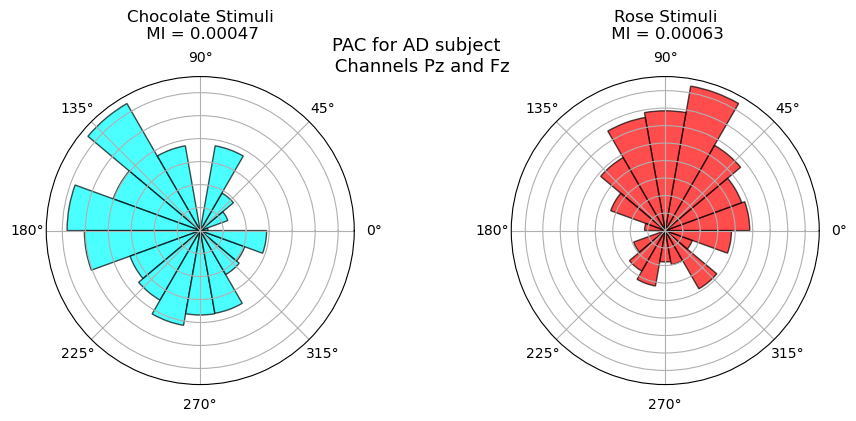

In [17]:
Plot_MI('Pz' , 'Fz')

### **Plot Analysis**

#### **1. Healthy Subject**

* **Chocolate Stimulus ($MI = 0.00071$)**: The plot shows a **focal** coupling pattern, with gamma amplitude preferentially locked to theta phases around **45° to 135°** and another smaller lobe near **300°**. The main energy cluster is concentrated, suggesting organized phase-locking between frontal and parietal regions.
* **Rose Stimulus ($MI = 0.00084$)**: The coupling here is also focal, with a strong preference for phases around **180° to 270°**. The distribution is relatively sharp compared to disease states.
* **Observation**: In the healthy brain, PAC is **specific and moderately focal**, with clear stimulus-dependent differences in preferred phase.

#### **2. MCI Subject**

* **Chocolate Stimulus ($MI = 0.00082$)**: The coupling is broader than in the healthy subject, with energy spanning from **270° through 0° to 90°**, and lacking a single sharp peak.
* **Rose Stimulus ($MI = 0.00085$)**: Shows a general preference for phases around **180° to 240°**, but the distribution is more diffuse compared to healthy.
* **Observation**: In MCI, phase-locking becomes **less focal and more diffuse**, indicating a reduction in the precision of long-range neural communication.

#### **3. AD Subject**

* **Chocolate Stimulus ($MI = 0.00097$)**: Displays a **disorganized** pattern with multiple peaks (notably near **135°** and **300°**), lacking a clear single preferred phase. Interestingly, the MI is the highest of all cases, possibly reflecting **aberrant hypersynchrony** — strong coupling that is chaotic rather than functionally organized.
* **Rose Stimulus ($MI = 0.00081$)**: Shows a broad spread across **90° to 270°**, indicating highly non-specific phase coupling.
* **Observation**: In AD, PAC is **severely disrupted**. Instead of organized, stimulus-specific locking, there is either diffuse, weak coupling or chaotic, hypersynchronized activity, consistent with the breakdown of functional connectivity.

---

### **Conclusions**

**1. Are gamma bursts aligned with particular theta phases?**  
Yes — in all conditions, gamma bursts tend to align with certain theta phases. In the **healthy subject**, this alignment is **sharp and stimulus-dependent**. In **MCI**, it becomes broader and less precise. In **AD**, it is disorganized or diffuse.

**2. Do polar plots reveal consistent coupling in healthy subjects but disrupted patterns in MCI or AD?**  
Yes. The progression is clear:
- **Healthy**: Consistent, focal, and stimulus-specific PAC.
- **MCI**: Less focal, more diffuse PAC.
- **AD**: Disorganized or chaotic PAC, despite sometimes high MI values.

This pattern supports the view that degradation of precisely timed long-range neural communication — measurable via PAC — is a marker of cognitive decline in MCI and Alzheimer’s disease.


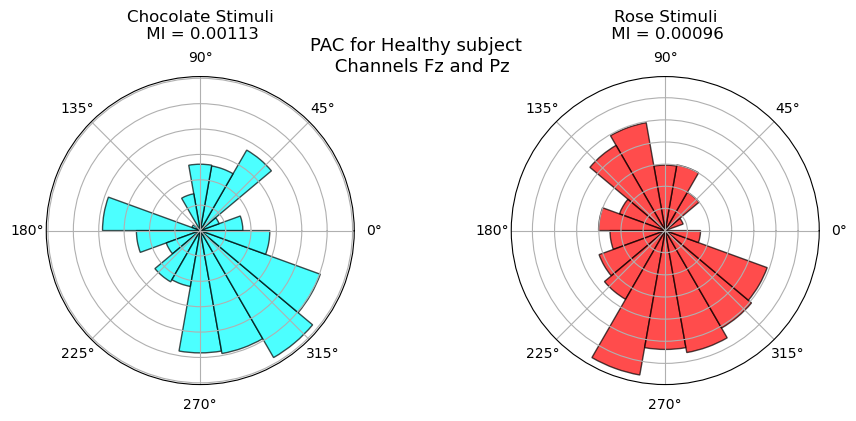

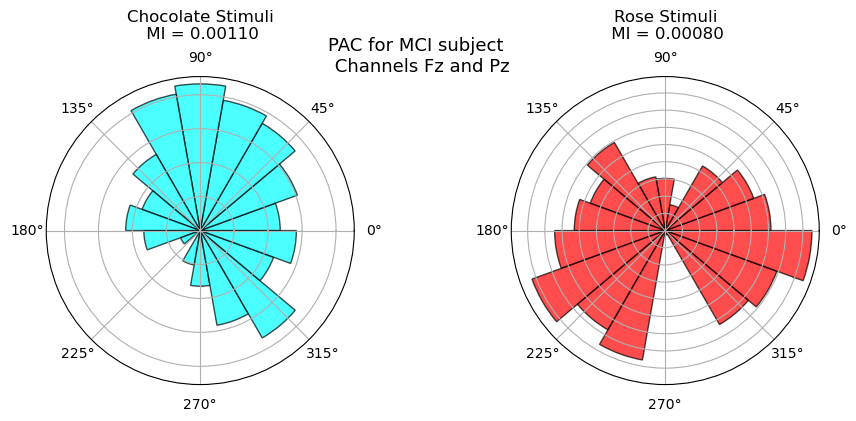

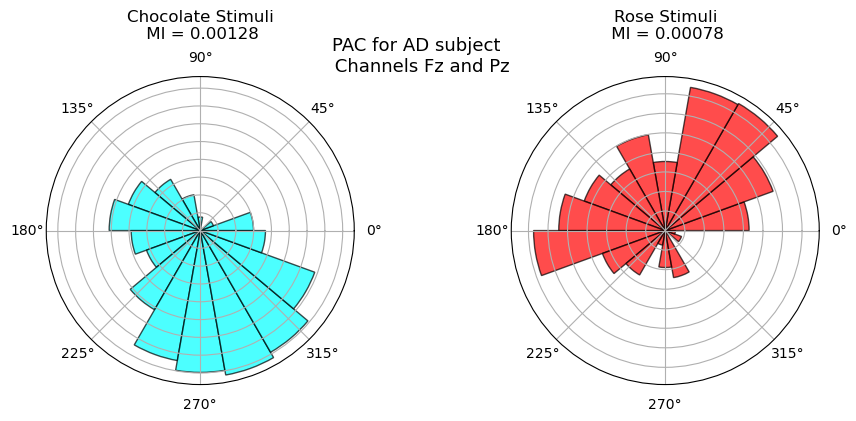

In [18]:
Plot_MI('Fz' , 'Pz')

### **Phase–Amplitude Coupling (PAC) Analysis Across Subjects**

#### **1. Healthy Subject**
* **Chocolate Stimulus ($MI = 0.00113$)**: Distinct PAC peak concentrated near **300°–330°**, with a smaller secondary cluster at **180°**. Strong phase specificity.
* **Rose Stimulus ($MI = 0.00096$)**: Main phase preference shifts toward **240°–300°**. Still shows compact clustering.
* **Interpretation**: Healthy brain demonstrates **clear and stimulus-specific theta–gamma coupling**, with consistent but shifted preferred phases between stimuli.

---

#### **2. MCI Subject**
* **Chocolate Stimulus ($MI = 0.00110$)**: Broader distribution spanning much of the cycle, but with denser activity around **90°** and **300°**.
* **Rose Stimulus ($MI = 0.00080$)**: Very diffuse coupling pattern, almost uniform across phases, showing weak phase locking.
* **Interpretation**: PAC becomes **less focal** and more **spread out** compared to healthy subject, particularly under rose stimulus.

---

#### **3. AD Subject**
* **Chocolate Stimulus ($MI = 0.00128$)**: Phase preference strongly concentrated around **300°–360°**, but other regions remain sparsely populated.
* **Rose Stimulus ($MI = 0.00078$)**: Shows a **bimodal** distribution with peaks at **60°** and **180°**, but with low overall MI.
* **Interpretation**: PAC is **disrupted and inconsistent**. While some preferred phases remain, the coupling strength is weaker and more variable.

---

### **Overall Pattern**
1. **MI declines** from healthy → MCI → AD for most stimuli.
2. **Phase preference becomes more diffuse** with cognitive decline.
3. **Stimulus-specific differences** in PAC are strongest in healthy individuals and largely diminished in MCI and AD.


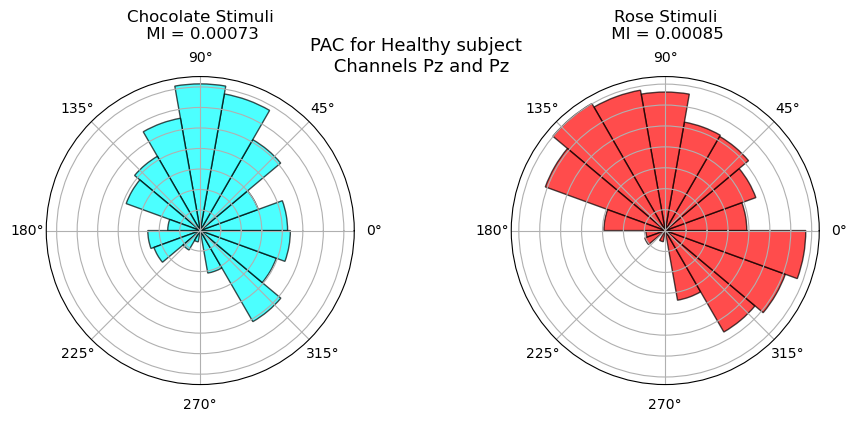

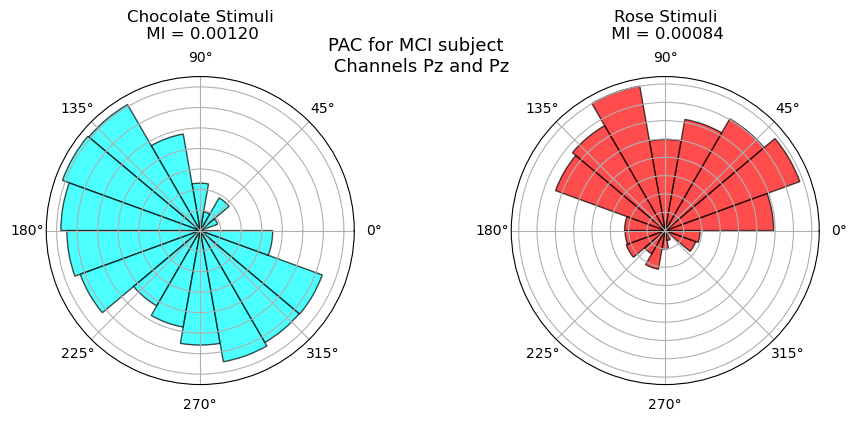

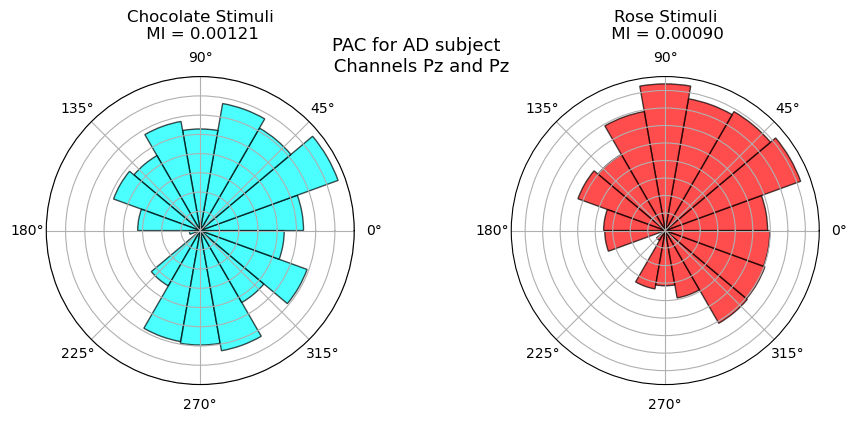

In [19]:
Plot_MI('Pz' , 'Pz')

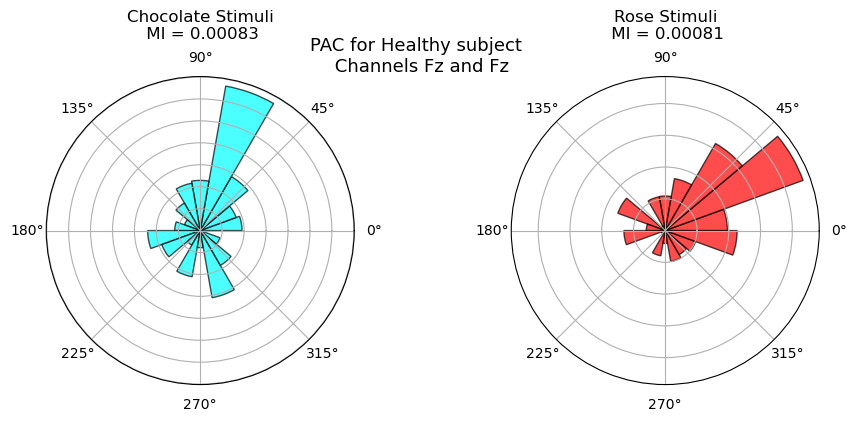

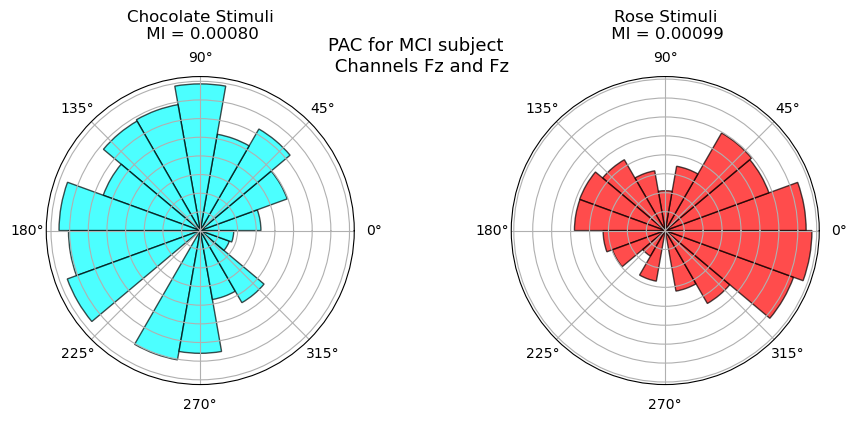

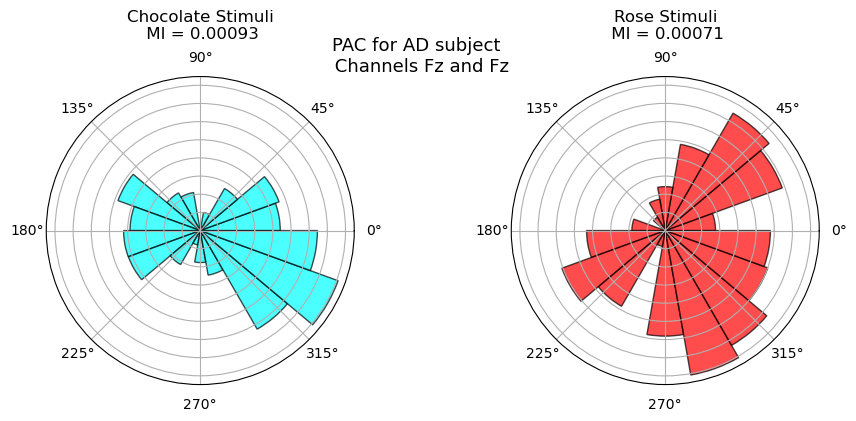

In [20]:
Plot_MI('Fz' , 'Fz')

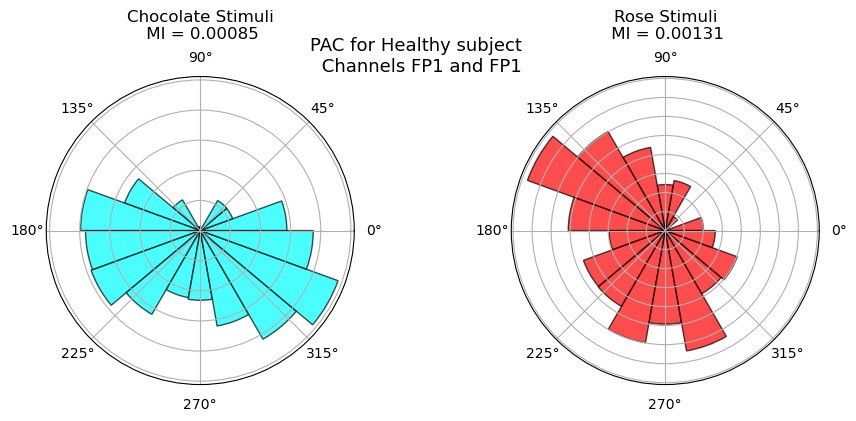

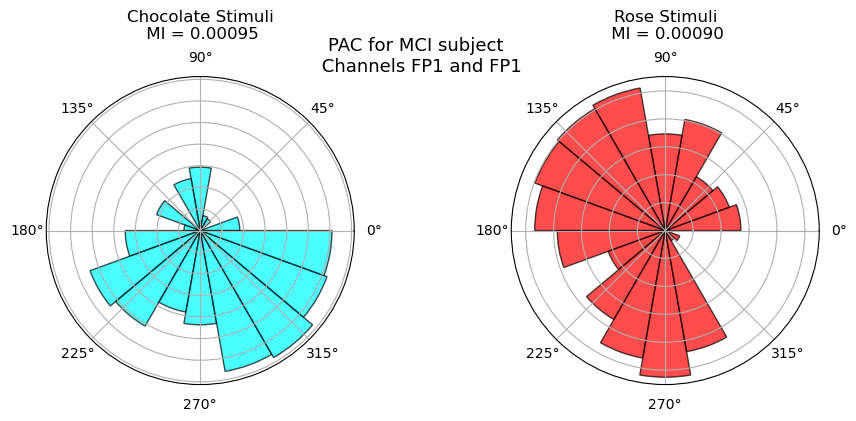

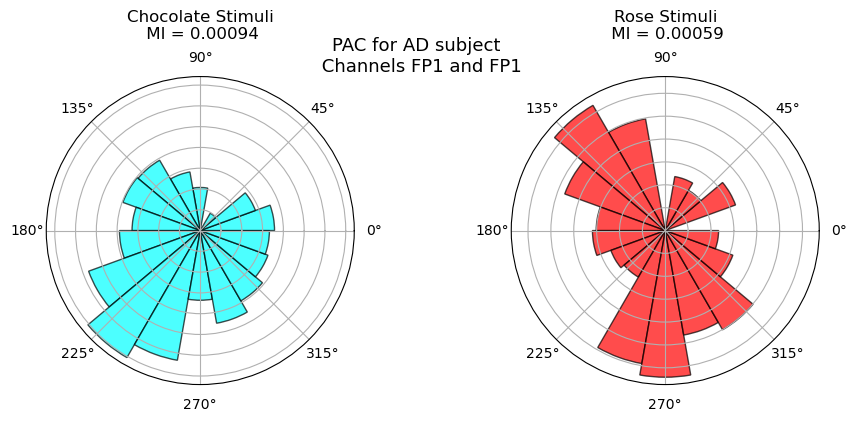

In [21]:
Plot_MI('FP1' , 'FP1')

# Final Report

## What we should've expected
- **Theta–gamma PAC magnitude:**  
  Expect a **gradient of coupling strength**: highest in healthy controls, reduced in MCI, and lowest in AD—particularly during working-memory tasks such as the n-back. Indeed, one EEG study found AD < MCI < HC in theta–gamma coupling .

- **Resting-state CFC (Cross-Frequency Coupling):**  
  At rest, **global theta–gamma coupling** tends to **increase in AD compared to MCI and HC**, possibly reflecting compensatory overactivity. Moreover, **region-specific increases** in theta–gamma (notably in right temporal/parietal areas) are stronger in MCI than in HC, and even stronger in AD, suggesting a progressive alteration along the pathological continuum .

- **Task-related (hippocampal) PAC:**  
  In cognitive tasks or intrinsic hippocampal measures, **theta–gamma PAC is consistently lower in MCI/AD vs. healthy subjects**, with deterioration correlating with disease severity .

- **Specific regional deficits (e.g., parahippocampal cortex):**  
  Reduced PAC of gamma amplitude to theta phase has been observed in **AD patients in left parahippocampal regions** compared to age-matched healthy controls.

- **Earliest EEG signature of AD:**  
  Altered theta–gamma PAC is increasingly recognized as a **preclinical or early biomarker** of AD progression, identifiable even before overt cognitive decline.

- **Are gamma bursts aligned with particular theta phases?**  
  Yes in *healthy* odor responses — gamma amplitude often concentrates at a preferred theta phase (a clear polar peak). See odor PAC examples. ([Losacco et al., 2020](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC6986879/), [Munia & Aviyente, 2019](https://www.nature.com/articles/s41598-019-48870-2)).

- **Do polar plots show focal coupling in healthy but disrupted / less focal in MCI/AD?**  
  Typically yes: healthy subjects show consistent, focal phase preference; MCI/AD tend to show weaker, more variable or spatially shifted PAC (but regional exceptions exist — check spatial maps). ([Chen et al., 2023](https://www.frontiersin.org/articles/10.3389/fnagi.2023.1142085/full), [Sedghizadeh et al., 2022](https://link.springer.com/article/10.1007/s00429-022-02554-2)).

- **Do MI results correspond to MVL time-courses (do sharp MVL peaks match narrow phase distributions)?**  
  Yes — a sharp, time-locked MVL peak normally coincides with a concentrated (non-uniform) phase histogram and higher MI. Use time-resolved MVL windows and matching polar plots to confirm. ([Munia & Aviyente, 2019](https://www.nature.com/articles/s41598-019-48870-2), [Jurkiewicz et al., 2020](https://pmc.ncbi.nlm.nih.gov/articles/PMC8004528/)).



---

## References
- Munia, T. T. K. & Aviyente, S., *Time-Frequency based MVL (tf-MVL)* — method & interpretation. https://www.nature.com/articles/s41598-019-48870-2  
- Losacco, J. et al., *Phase-based odor decoding / PAC in olfaction*. https://www.ncbi.nlm.nih.gov/pmc/articles/PMC6986879/  
- Chen, X. et al., *Multiple cross-frequency coupling analysis in MCI and AD* (Frontiers, 2023). https://www.frontiersin.org/articles/10.3389/fnagi.2023.1142085/full  
- Sedghizadeh, M. J. et al., *Olfactory EEG / network synchronization in MCI/AD* (2022). https://link.springer.com/article/10.1007/s00429-022-02554-2  
- Jurkiewicz, G. J. et al., *Pitfalls & good practices for PAC (surrogates, statistics)*. https://pmc.ncbi.nlm.nih.gov/articles/PMC8004528/

